# LVGP vs lvgp_mixed on the October tensile data — which model to use (preliminary)

**Question.** Two latent-variable GP models are candidates for the property models of this project: the **LVGP** (the
standard model for mixed categorical + continuous inputs) and **lvgp_mixed** (the LVGP plus a trend shared by all levels and
per-level offsets). Which one predicts these data better?

**Data.** The latest delivery, `raw_data/10_26_26/`: the 12 formulations of the August DoE, all at recycle cycle 0, 44
specimens; 42 kept after setting aside the same two as `notebooks/data_processing_v4.ipynb` (f11_s3 failed, f08_s1 superseded).
Inputs: polymer system (categorical: PP, HDPE, TPU, each with PAL), PAL % and extrusion temperature. Responses: UTS, Young's
modulus, strain at break, toughness.

**How.** The modeling unit is the formulation (12 design points): the mean of log(response) over its specimens, with the
variance of that mean as known noise. Both models are fitted to these 12 means; they are compared by leaving one formulation
out at a time and predicting it from the other 11.

**Status (2026-10-28).** The models in `models/` are verbatim copies of the lvgp_kernel study's code; `check_same_as_cat_kernel.py`
confirms bit-identical predictions (PASS in `ml_gp_env` and in the base anaconda environment). Background on both models, the provenance of the code and the check: `README.md`. The comparison is
**preliminary**: 12 formulations, 4 per polymer, a single recycle level. **Nothing is written by default.**

In [1]:
import os, sys, warnings
from pathlib import Path

HERE = Path.cwd()
MODELING = HERE if (HERE / "lvgp_compare.py").exists() else HERE / "modeling"
ROOT = MODELING.parent
for p_ in (str(MODELING), str(ROOT)):
    if p_ not in sys.path:
        sys.path.insert(0, p_)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import wilcoxon

import lvgp_compare as LC
from models import MODELS

torch.set_num_threads(1)                         # one thread: fits reproducible to the bit
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
FIG_DIR = MODELING / "figures"                   # used only when a SAVE_FIG switch is True
M_COL = {"lvgp": "#eb6834", "lvgp_mixed": "#1baf7a", "polymer_mean": "#8a8985", "global_mean": "#c9c7c0"}

---
## 1 — Data

Per-specimen properties from the project's parser (`utils/instron.py`), then one row per formulation.

In [2]:
kept = LC.load_tensile(str(ROOT))
print(f"{len(kept)} specimens, {kept['formulation'].nunique()} formulations, polymers: {sorted(kept['polymer_system'].unique())}")
design = LC.formulation_table(kept, "max_tensile_stress_MPa")[["formulation", "polymer", "pal", "temp", "n"]]
design

42 specimens, 12 formulations, polymers: ['HDPE+PAL', 'PP+PAL', 'TPU+PAL']


,formulation,polymer,pal,temp,n
0,3,PP+PAL,15,225,5
1,4,PP+PAL,28,180,3
2,12,PP+PAL,30,230,4
3,6,PP+PAL,41,205,3
4,10,HDPE+PAL,19,195,4
5,2,HDPE+PAL,23,235,4
6,9,HDPE+PAL,35,200,3
7,1,HDPE+PAL,49,220,3
8,7,TPU+PAL,11,200,3
9,11,TPU+PAL,23,215,3


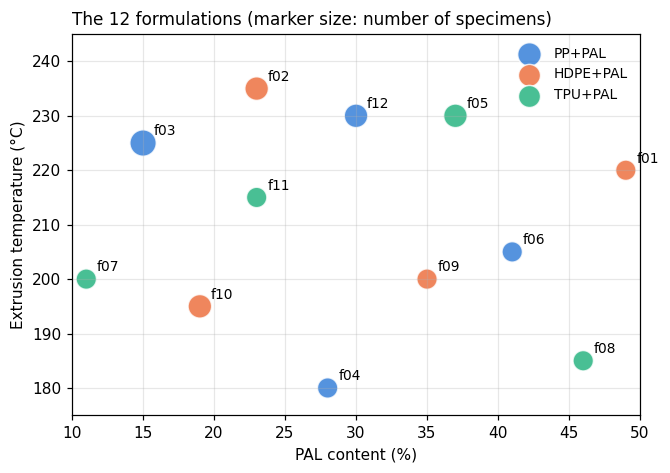

In [3]:
SAVE_FIG = False                                 # True -> write the figure to modeling/figures/
FIG_NAME = "design_space"

fig, ax = plt.subplots(figsize=(6.2, 4.4))
for p, col in LC.POLY_COLORS.items():
    d = design[design["polymer"] == p]
    ax.scatter(d["pal"], d["temp"], s=60 * d["n"], color=col, alpha=.8, label=p, edgecolor="white")
    for _, r in d.iterrows():
        ax.annotate(f"f{r['formulation']:02d}", (r["pal"], r["temp"]), xytext=(7, 5), textcoords="offset points", fontsize=9)
ax.set_xlim(*LC.BOUNDS[0]); ax.set_ylim(LC.BOUNDS[1][0] - 5, LC.BOUNDS[1][1] + 5)
ax.set_xlabel("PAL content (%)"); ax.set_ylabel("Extrusion temperature (°C)"); ax.grid(alpha=.3)
ax.set_title("The 12 formulations (marker size: number of specimens)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper right")
plt.tight_layout()
if SAVE_FIG:
    FIG_DIR.mkdir(exist_ok=True); fig.savefig(FIG_DIR / f"{FIG_NAME}.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 2 — What the data look like

Each response against PAL %, per polymer: small dots are specimens, large dots the formulation means (geometric mean, as the
models see them); the label is the extrusion temperature. Log scale throughout.

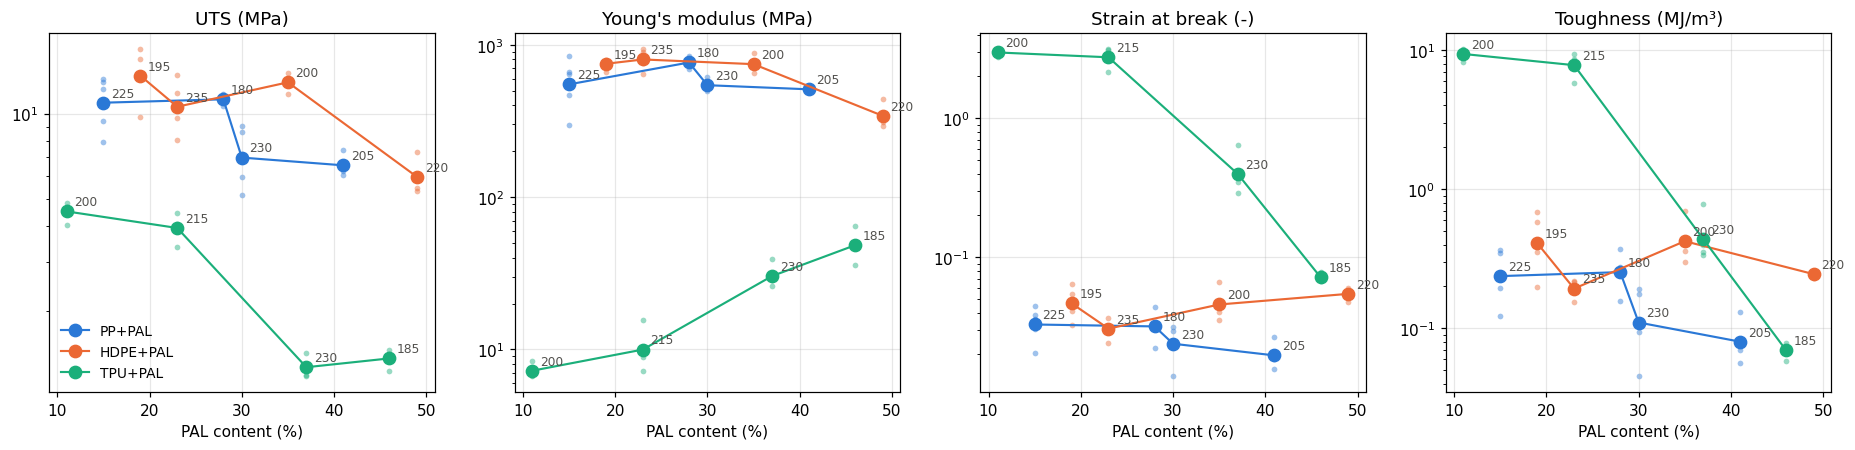

In [4]:
SAVE_FIG = False                                 # True -> write the figure to modeling/figures/
FIG_NAME = "responses_vs_pal"

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, (r, lab) in zip(axes, LC.RESPONSES.items()):
    t = LC.formulation_table(kept, r)
    for p, col in LC.POLY_COLORS.items():
        s = kept[kept["polymer_system"] == p]
        ax.scatter(s["pal_pct"], s[r], s=14, color=col, alpha=.45, lw=0)
        m = t[t["polymer"] == p].sort_values("pal")
        ax.plot(m["pal"], np.exp(m["mean_log"]), "o-", color=col, ms=8, lw=1.4, label=p)
        for _, row in m.iterrows():
            ax.annotate(f"{row['temp']:.0f}", (row["pal"], np.exp(row["mean_log"])), xytext=(5, 4), textcoords="offset points",
                        fontsize=8, color="#52514e")
    ax.set_yscale("log"); ax.set_title(lab, fontsize=12); ax.set_xlabel("PAL content (%)"); ax.grid(alpha=.3)
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
if SAVE_FIG:
    FIG_DIR.mkdir(exist_ok=True); fig.savefig(FIG_DIR / f"{FIG_NAME}.png", dpi=200, bbox_inches="tight")
plt.show()

**Replicate scatter and the noise the models are told about.** For every formulation: the standard deviation of log(response)
over its specimens (≈ the coefficient of variation) and the standard deviation of the formulation mean, which is the known
noise each model gets for that point.

In [5]:
rows = []
for r in LC.RESPONSES:
    t = LC.formulation_table(kept, r)
    rows.append({"response": LC.RESPONSES[r], "median sd of log (specimens)": float(np.sqrt(t["var_log"]).median()),
                 "median sd of the mean": float(np.sqrt(t["var_mean"]).median()),
                 "sd of the 12 means": float(t["mean_log"].std()),
                 "sd of the means within a polymer": float(t.groupby("polymer")["mean_log"].std().mean())})
noise = pd.DataFrame(rows).set_index("response")
noise.round(3)

,median sd of log (specimens),median sd of the mean,sd of the 12 means,sd of the means within a polymer
response,,,,
UTS (MPa),0.125,0.072,0.811,0.446
Young's modulus (MPa),0.160,0.086,1.806,0.495
Strain at break (-),0.285,0.143,1.774,0.755
Toughness (MJ/m³),0.415,0.199,1.576,1.109


---
## 3 — The two models

Both are Gaussian processes on (x, c): x = (PAL %, temperature) scaled to [0, 1], c = the polymer level. The categorical input
is handled through a **latent map**: every level gets a learned point z(c) in a 2-D latent space, and levels that behave alike end
up close together (the first level is fixed at the origin, the second on the first axis).

**LVGP** (Zhang, Tao, Chen & Apley 2020, *Technometrics*): one product kernel,

$$k\big((x,c),(x',c')\big) = \sigma^2\, k_x(x,x')\,\exp\!\big(-\tfrac12\lVert z(c)-z(c')\rVert^2\big),
\qquad k_x(x,x') = \exp\!\Big(-\tfrac12\textstyle\sum_j (x_j-x'_j)^2/\ell_j^2\Big).$$

Every level has its own response surface; how much the levels share is set by their distance in the latent space.

**lvgp_mixed** (the mixed kernel of the lvgp_kernel study, "version 13"; modeled on BoTorch's `MixedSingleTaskGP`): the same
product part plus an additive part,

$$k = \underbrace{\sigma_s^2\big[k_x^{(1)}(x,x') + \sigma_z^2\, k_z^{(1)}(c,c')\big]}_{\text{additive: a trend shared by all levels + level offsets}}
\;+\; \underbrace{\sigma_p^2\, k_x^{(2)}(x,x')\, k_z^{(2)}(c,c')}_{\text{multiplicative: level-specific shapes (the LVGP)}},$$

with two independent x-kernels, the two latent kernels sharing one latent map z(c), and **no prior on the three output scales**
σ²ₛ, σ²_z, σ²ₚ (the original mixed kernel had one; the study found removing it more accurate). Setting σ²ₛ = 0 gives back the
LVGP, so lvgp_mixed can represent everything the LVGP can, at the price of more hyperparameters to estimate.

**What the study found on test functions** (noiseless benchmark, 24 tests): lvgp_mixed has about 0.4 of the LVGP's error where
the levels share structure, but loses slightly (0–7 %) on Hartmann, and it has rare failures where it misses the level structure.
Here the question is which one these 12 formulations support.

**Fitting.** Both: MAP fit with L-BFGS-B from 3 starts (the default plus two drawn from the priors), inputs scaled by the DoE
ranges (PAL 10–50 %, temperature 180–240 °C), y standardized, fixed noise = variance of the formulation mean, floored at 10⁻⁴ of
the variance of y.

---
## 4 — Both models on all 12 formulations

Fit per response; the number of fitted hyperparameters, the LVGP's latent positions of the three polymers, and lvgp_mixed's
split of the variance between its shared trend, offsets and level-specific part.

In [6]:
fits = {}
rows, lat, shares = [], [], []
for r in LC.RESPONSES:
    data, _ = LC.formulation_data(kept, r)
    for key in ("lvgp", "lvgp_mixed"):
        m = LC.fit(key, data, seed=0)
        fits[(r, key)] = m
        n_par = sum(int(p.numel()) for p in m.model.parameters() if p.requires_grad)
        rows.append({"response": LC.RESPONSES[r], "model": key, "fitted hyperparameters": n_par})
        z = LC.latent_positions(m); z["response"] = LC.RESPONSES[r]; z["model"] = key; lat.append(z)
    s = LC.mixed_shares(fits[(r, "lvgp_mixed")]); s["response"] = LC.RESPONSES[r]; shares.append(s)
display(pd.DataFrame(rows).pivot(index="response", columns="model", values="fitted hyperparameters"))
display(pd.DataFrame(shares).set_index("response")[["share_trend", "share_offset", "share_level"]].round(3))

model,lvgp,lvgp_mixed
response,,
Strain at break (-),11,16
Toughness (MJ/m³),11,16
UTS (MPa),11,16
Young's modulus (MPa),11,16


,share_trend,share_offset,share_level
response,,,
UTS (MPa),0.014,0.647,0.339
Young's modulus (MPa),0.000,0.687,0.313
Strain at break (-),0.000,0.097,0.903
Toughness (MJ/m³),0.000,0.000,1.000


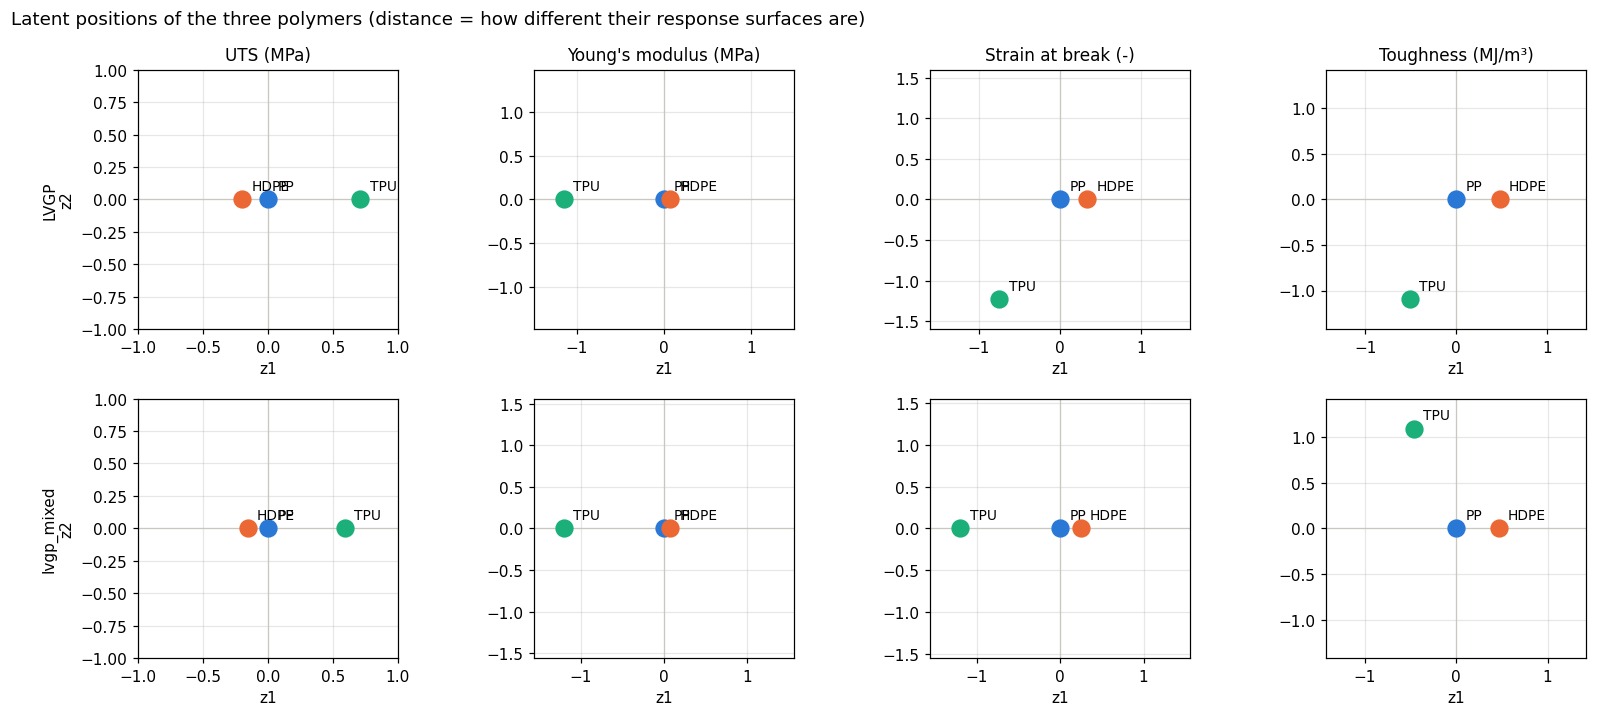

In [7]:
SAVE_FIG = False                                 # True -> write the figure to modeling/figures/
FIG_NAME = "latent_maps"

L = pd.concat(lat).reset_index().rename(columns={"index": "polymer"})
fig, axes = plt.subplots(2, 4, figsize=(15, 6.6))
for i, key in enumerate(("lvgp", "lvgp_mixed")):
    for j, (r, lab) in enumerate(LC.RESPONSES.items()):
        ax = axes[i, j]; d = L[(L["model"] == key) & (L["response"] == lab)]
        for _, row in d.iterrows():
            ax.scatter(row["z1"], row["z2"], s=120, color=LC.POLY_COLORS[row["polymer"]], zorder=3)
            ax.annotate(row["polymer"].split("+")[0], (row["z1"], row["z2"]), xytext=(6, 6), textcoords="offset points", fontsize=9)
        lim = max(1.0, float(np.abs(d[["z1", "z2"]].to_numpy()).max()) * 1.3)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(alpha=.3)
        ax.axhline(0, color="#c9c7c0", lw=.8); ax.axvline(0, color="#c9c7c0", lw=.8)
        if i == 0: ax.set_title(lab, fontsize=11)
        if j == 0: ax.set_ylabel(f"{LC.LABELS[key]}\nz2")
        ax.set_xlabel("z1")
fig.suptitle("Latent positions of the three polymers (distance = how different their response surfaces are)", x=.01, ha="left")
plt.tight_layout()
if SAVE_FIG:
    FIG_DIR.mkdir(exist_ok=True); fig.savefig(FIG_DIR / f"{FIG_NAME}.png", dpi=200, bbox_inches="tight")
plt.show()

Both models place PP and HDPE almost on top of each other and TPU far away, for every response: the two polyolefins behave alike and TPU is different, as the ANOVA of `data_processing_v4.ipynb` found (polymer dominates). lvgp_mixed switches its shared trend off (0–1 % of the variance) and, for UTS and modulus, puts about two thirds of the variance into per-polymer offsets; for strain and toughness it is essentially the LVGP (90–100 % level-specific).

**Partial dependence**, the view of `notebooks/data_processing_v4.ipynb` section 6, now from each of the two models: per polymer,
the response against PAL % averaged over temperature (top) and against temperature averaged over PAL % (bottom), with a 5–95 %
band from joint posterior draws of the fitted function (specimen noise left out).

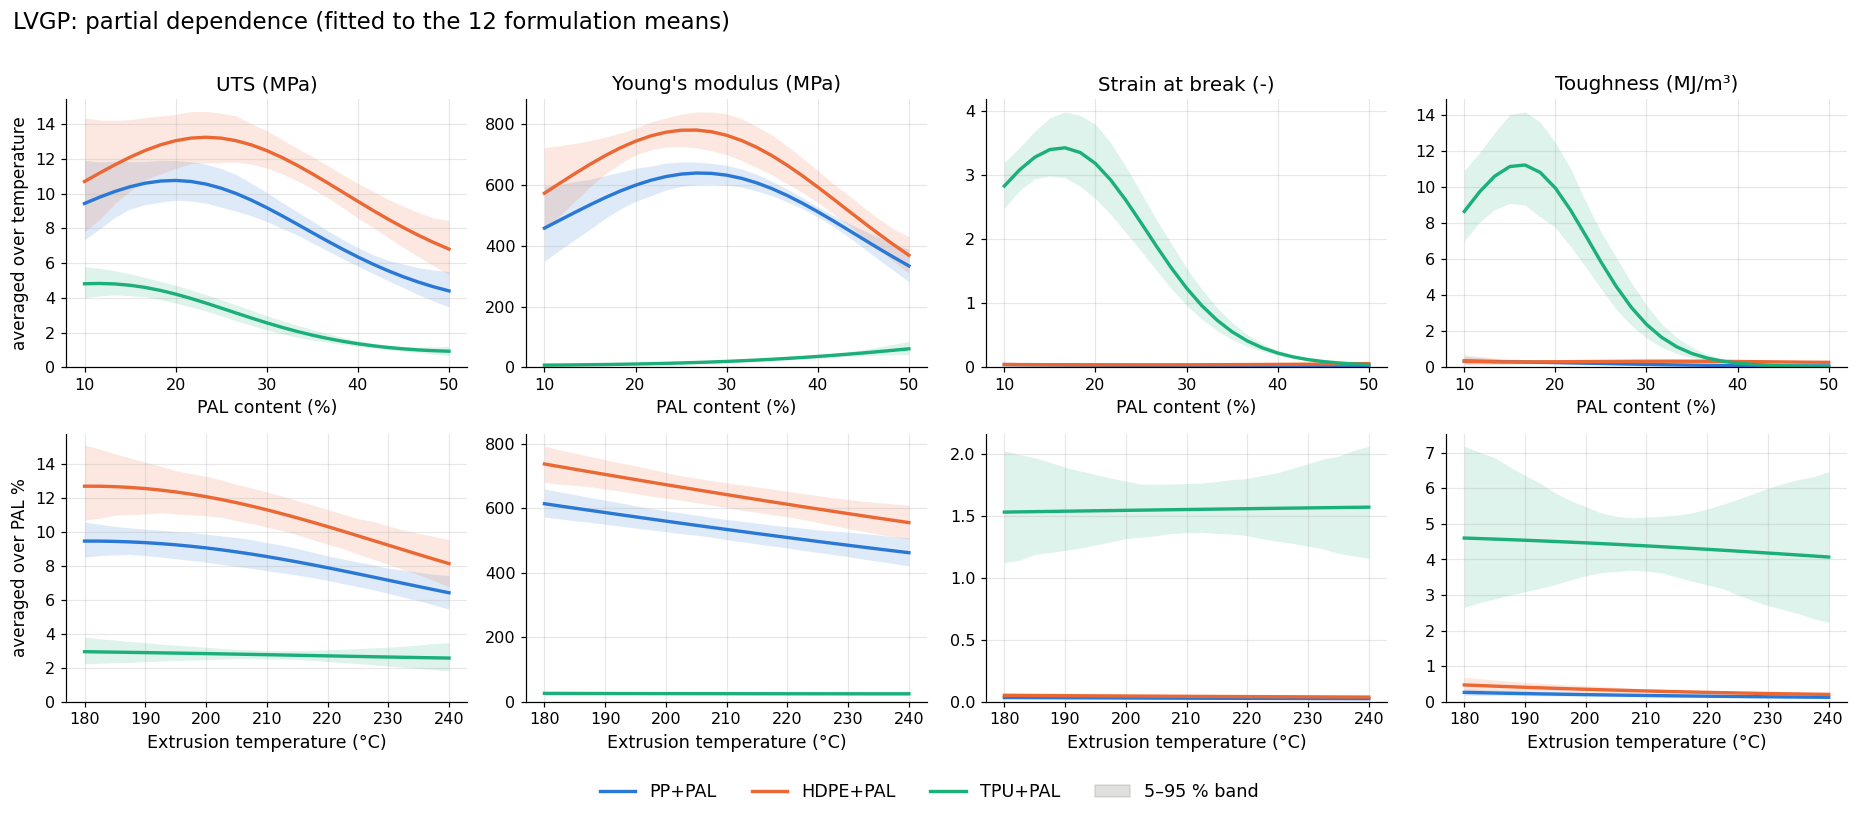

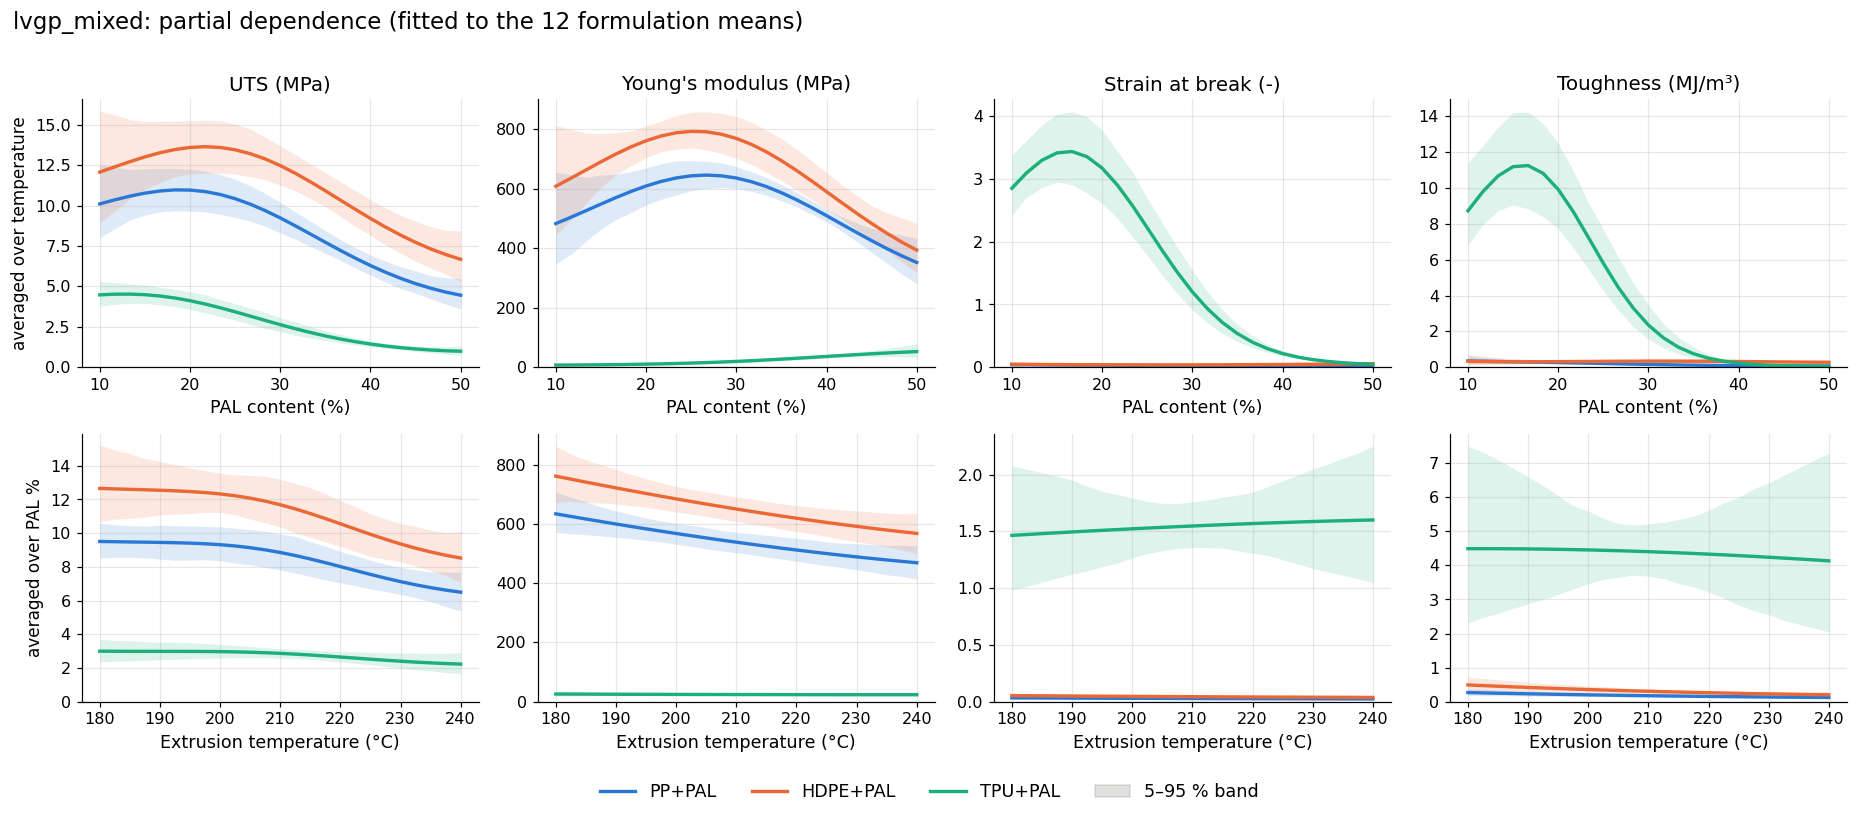

In [8]:
SAVE_FIG = False                                 # True -> write the figures to modeling/figures/
FIG_NAME = "partial_dependence"

for key in ("lvgp", "lvgp_mixed"):
    pds = {r: LC.partial_dependence(fits[(r, key)]) for r in LC.RESPONSES}
    save = None
    if SAVE_FIG:
        FIG_DIR.mkdir(exist_ok=True); save = FIG_DIR / f"{FIG_NAME}_{key}.png"
    LC.plot_partial_dependence(pds, title=f"{LC.LABELS[key]}: partial dependence (fitted to the 12 formulation means)", save=save)
    plt.show()

Fitted to all 12 formulations, the two models draw nearly the same surfaces, and both reproduce the GP of `data_processing_v4.ipynb`: UTS falls with PAL in every polymer, TPU's strain and toughness collapse above about 30 % PAL while its modulus rises, and temperature has little effect. They differ when they have to predict a formulation they have not seen, which is what the next section tests.

---
## 5 — Leave-one-formulation-out comparison

For each of the 12 formulations: fit both models to the other 11 and predict the left-out mean (log scale); 3 fitting seeds
per fit, averaged (they barely differ). Two baselines without a GP: the mean of the same polymer's other formulations, and the
mean of all other formulations.

Scores, per response:
* **RMSE of log(response)** — the main score; 0.1 ≈ 10 % error.
* **median absolute relative error** in %.
* **NLPD** — mean negative log predictive density: rewards accurate *and* honest uncertainty (lower is better).
* **within 2 sd** — share of left-out formulations inside the ±2 sd predictive interval (≈ 95 % if calibrated).

About 6 minutes with 24 processes.

In [9]:
LOAD_CV = False                                  # True -> read the results from CV_FILE instead of refitting
SAVE_CV = False                                  # True -> write the results to CV_FILE
CV_FILE = MODELING / "results" / "lofo_cv.csv"

if LOAD_CV and CV_FILE.exists():
    cv = pd.read_csv(CV_FILE)
else:
    cv = pd.concat([LC.lofo(kept, r, seeds=(0, 1, 2), workers=24) for r in LC.RESPONSES], ignore_index=True)
if SAVE_CV:
    CV_FILE.parent.mkdir(exist_ok=True); cv.to_csv(CV_FILE, index=False)
summ = LC.summarize(cv)
summ["response"] = summ["response"].map(LC.RESPONSES)
summ.pivot(index="model", columns="response", values=["rmse_log", "median_abs_rel_err_pct", "nlpd", "within_2sd"]).round(3)

rmse_log                                                   median_abs_rel_err_pct                                                                  nlpd                    \
response     Strain at break (-) Toughness (MJ/m³) UTS (MPa) Young's modulus (MPa)    Strain at break (-) Toughness (MJ/m³) UTS (MPa) Young's modulus (MPa) Strain at break (-) Toughness (MJ/m³)   
model                                                                                                                                                                                               
global_mean                1.853             1.646     0.847                 1.886                228.072            89.386    91.118               352.247               2.174             2.083   
lvgp                       0.915             1.420     0.343                 0.258                 47.371            90.285    26.534                28.505               2.265             2.762   
lvgp_mixed                 1.163             1.498     0.359                 0.508                 77.096            83.342    36.703                33.123               2.360             2.691   
polymer_mean               1.206             1.646     0.550                 0.668                 41.948            89.762    45.296                41.125               1.285             1.460   

                                                      within_2sd                                                    
response     UTS (MPa) Young's modulus (MPa) Strain at break (-) Toughness (MJ/m³) UTS (MPa) Young's modulus (MPa)  
model                                                                                                               
global_mean      1.367                 2.120               0.833             0.833     0.833                 0.917  
lvgp             1.601                 0.580               0.611             0.500     0.667                 0.667  
lvgp_mixed       2.343                 2.627               0.500             0.583     0.694                 0.667  
polymer_mean     1.179                 2.776               0.833             1.000     0.917                 0.833

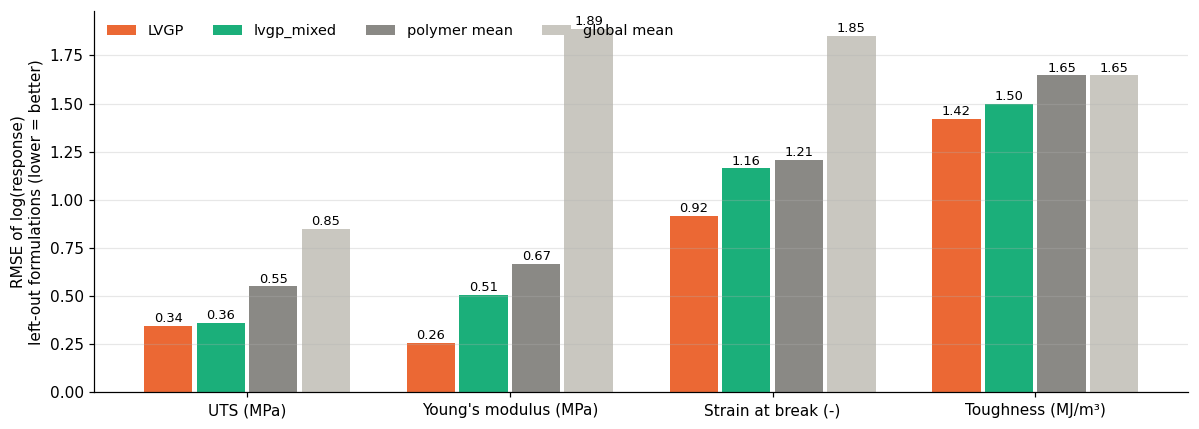

In [10]:
SAVE_FIG = False                                 # True -> write the figure to modeling/figures/
FIG_NAME = "lofo_rmse"

order = ["lvgp", "lvgp_mixed", "polymer_mean", "global_mean"]
fig, ax = plt.subplots(figsize=(11, 4))
resp = list(LC.RESPONSES.values()); x = np.arange(len(resp)); w = .2
for i, k in enumerate(order):
    v = [float(summ[(summ["model"] == k) & (summ["response"] == r)]["rmse_log"].iloc[0]) for r in resp]
    b = ax.bar(x + (i - 1.5) * w, v, w * .92, color=M_COL[k], label=LC.LABELS[k])
    for xi, vi in zip(x + (i - 1.5) * w, v):
        ax.text(xi, vi + .02, f"{vi:.2f}", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(resp); ax.set_ylabel("RMSE of log(response)\nleft-out formulations (lower = better)")
ax.legend(frameon=False, ncol=4, fontsize=9.5, loc="upper left"); ax.grid(axis="y", alpha=.3)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout()
if SAVE_FIG:
    FIG_DIR.mkdir(exist_ok=True); fig.savefig(FIG_DIR / f"{FIG_NAME}.png", dpi=200, bbox_inches="tight")
plt.show()

**Formulation by formulation.** The absolute error of each left-out formulation (seed average), LVGP against lvgp_mixed:
points below the diagonal are formulations where lvgp_mixed is closer. The title gives how often the LVGP is closer and a paired
Wilcoxon test over the 12 formulations.

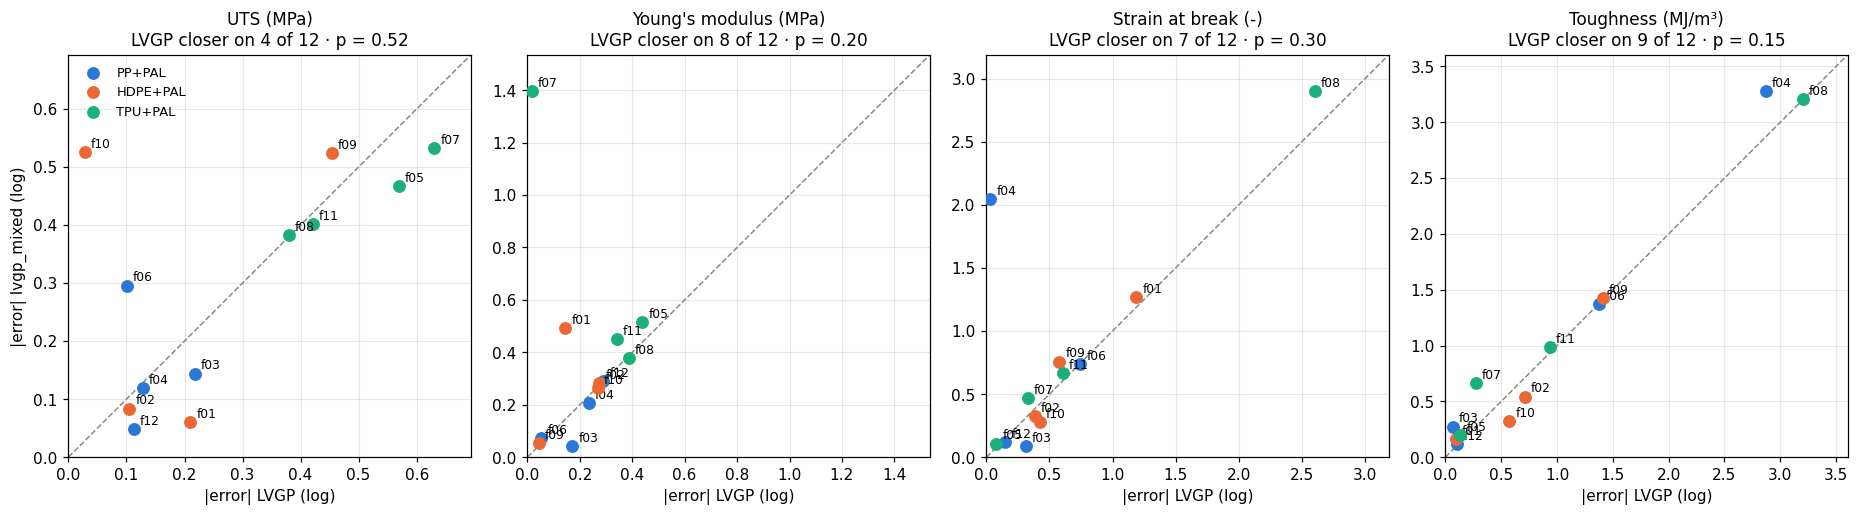

,LVGP closer (of 12),Wilcoxon p
response,,
UTS (MPa),4,0.519
Young's modulus (MPa),8,0.204
Strain at break (-),7,0.301
Toughness (MJ/m³),9,0.151


In [11]:
SAVE_FIG = False                                 # True -> write the figure to modeling/figures/
FIG_NAME = "lofo_paired"

paired = []
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
for ax, (r, lab) in zip(axes, LC.RESPONSES.items()):
    d = cv[(cv["response"] == r) & cv["model"].isin(["lvgp", "lvgp_mixed"])]
    e = d.groupby(["formulation", "polymer", "model"])["err"].apply(lambda s: float(np.abs(s).mean())).unstack().reset_index()
    for p, col in LC.POLY_COLORS.items():
        s = e[e["polymer"] == p]
        ax.scatter(s["lvgp"], s["lvgp_mixed"], s=55, color=col, label=p, zorder=3)
        for _, row in s.iterrows():
            ax.annotate(f"f{row['formulation']:02d}", (row["lvgp"], row["lvgp_mixed"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
    hi = float(e[["lvgp", "lvgp_mixed"]].to_numpy().max()) * 1.1
    ax.plot([0, hi], [0, hi], color="#8a8985", lw=1, ls="--"); ax.set_xlim(0, hi); ax.set_ylim(0, hi); ax.set_aspect("equal")
    wins, p_ = int((e["lvgp"] < e["lvgp_mixed"]).sum()), float(wilcoxon(e["lvgp"], e["lvgp_mixed"]).pvalue)
    paired.append({"response": lab, "LVGP closer (of 12)": wins, "Wilcoxon p": round(p_, 3)})
    ax.set_title(f"{lab}\nLVGP closer on {wins} of 12 · p = {p_:.2f}", fontsize=11)
    ax.set_xlabel("|error| LVGP (log)"); ax.grid(alpha=.3)
axes[0].set_ylabel("|error| lvgp_mixed (log)"); axes[0].legend(frameon=False, fontsize=8.5, loc="upper left")
plt.tight_layout()
if SAVE_FIG:
    FIG_DIR.mkdir(exist_ok=True); fig.savefig(FIG_DIR / f"{FIG_NAME}.png", dpi=200, bbox_inches="tight")
plt.show()
pd.DataFrame(paired).set_index("response")

In [12]:
# the largest left-out errors, both models (seed average, log scale; exp(|error|) - 1 = relative error)
big = (cv[cv["model"].isin(["lvgp", "lvgp_mixed"])].groupby(["response", "formulation", "polymer", "model"])["err"].mean()
       .unstack().reset_index())
big["response"] = big["response"].map(LC.RESPONSES)
big["worse"] = np.where(big["lvgp"].abs() > big["lvgp_mixed"].abs(), "LVGP", "lvgp_mixed")
big["largest |error|"] = big[["lvgp", "lvgp_mixed"]].abs().max(axis=1)
big.sort_values("largest |error|", ascending=False).head(8).round(3)

model,response,formulation,polymer,lvgp,lvgp_mixed,worse,largest |error|
27,Toughness (MJ/m³),4,PP+PAL,-2.869,-3.278,lvgp_mixed,3.278
31,Toughness (MJ/m³),8,TPU+PAL,3.200,3.206,lvgp_mixed,3.206
19,Strain at break (-),8,TPU+PAL,2.604,2.902,lvgp_mixed,2.902
15,Strain at break (-),4,PP+PAL,-0.031,-2.043,lvgp_mixed,2.043
32,Toughness (MJ/m³),9,HDPE+PAL,-1.410,-1.422,lvgp_mixed,1.422
42,Young's modulus (MPa),7,TPU+PAL,-0.018,1.396,lvgp_mixed,1.396
29,Toughness (MJ/m³),6,PP+PAL,1.380,1.372,LVGP,1.380
12,Strain at break (-),1,HDPE+PAL,-1.187,-1.268,lvgp_mixed,1.268


---
## 6 — Preliminary verdict (2026-10-28)

**Use the LVGP for these data.**

* **Accuracy.** Leaving one formulation out at a time, the LVGP has the lower error on all four responses: RMSE of
  log(response) 0.34 vs 0.36 (UTS), 0.26 vs 0.51 (modulus), 0.92 vs 1.16 (strain at break), 1.42 vs 1.50 (toughness). Both
  GPs beat the polymer-mean and global-mean baselines on UTS, modulus and strain; on toughness nothing predicts a left-out
  formulation well (global mean 1.65).
* **Where the difference comes from.** Not from a uniform shift: the LVGP is closer on 4, 8, 7 and 9 of the 12 formulations,
  and no paired test is significant (Wilcoxon p = 0.52, 0.20, 0.30, 0.15). lvgp_mixed's higher RMSE comes from a few large
  misses on a left-out formulation — f07's modulus (|error| 1.40 against the LVGP's 0.02) and f04's strain (2.04 against 0.03) —
  the kind of failure the study also saw on its test functions.
* **Why, most likely.** These are measured data with scatter and with differences between formulations that the three inputs
  do not explain (lack of fit), fitted from 11 points at a time. lvgp_mixed has more hyperparameters (section 4) and no prior on
  its three output scales, so on some left-out sets it fits a shared trend or offset that does not hold for the missing
  formulation. On the study's noiseless test functions, even with 5 points per level, lvgp_mixed was the more accurate model;
  the difference here is the data, not only their number.
* **Uncertainty.** Both GPs are over-confident: only 50–70 % of the left-out formulations fall within ±2 sd (95 % expected).
  The noise they are given is the scatter of the formulation mean (3–5 specimens), but the formulations also differ in ways
  the 3 inputs do not explain (the v4 ANOVA found lack of fit for every response). Treat their intervals as too narrow.

**Caveats and next steps.** Preliminary: 12 formulations, all at recycle cycle 0. Re-run when the 5× / 10× recycle levels or the
second DoE arrive (`lofo` takes any `kept` table). Worth testing then: learning an extra noise term (nugget) for the lack of fit,
and whether lvgp_mixed catches up with more points per polymer.